<a href="https://colab.research.google.com/github/MHadiShahid/SentientURL/blob/main/SentientURL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛡️ SentinelURL: Proactive & Intelligent Phishing Detection

Phishing remains one of the most damaging forms of cybercrime, causing billions of dollars in losses annually. Traditional defense mechanisms, such as static blacklisting, are fundamentally reactive and fail against newly generated phishing domains—many of which stay active for only hours before being replaced.

### 🚀 Project Overview
**SentinelURL** addresses this critical limitation by developing a proactive, intelligent system that analyzes the structural and lexical features of any URL to determine its threat level in real-time, completely bypassing the need for historical blacklists.

### 🌟 Target Impact
- **Cybersecurity Industry:** Provides dynamic, real-time indicator-of-compromise (IoC) evaluations.
- **Financial Institutions:** Mitigates brand spoofing and protects customer transactions.
- **Everyday Users:** Secures browsing sessions on the fly.

### 📊 Machine Learning Implementation
To construct a comprehensive defense framework, this project implements **six distinct machine learning algorithm categories**:
1. **Classification** (KNN, SVM, Decision Tree)
2. **Regression** (Linear Regression for Maliciousness Scoring)
3. **Clustering** (K-Means)
4. **Reinforcement Learning** (Q-Learning Agent)
5. **Ensemble Methods** (Random Forest, XGBoost)

In [1]:
!pip install xgboost -q

  SentinelURL — Phishing URL Detection

[1/8] Loading dataset...
   Dataset shape : (44329, 51)
   Phishing URLs : 26124
   Legit URLs    : 18204

[2/8] Preprocessing...
   Missing values : 26
   Duplicates     : 26
   Stratified sample : 29998 rows
   Features after variance filter    : 38
   Features after correlation filter : 36
   Train size : 26998  |  Test size : 3000
   PCA 95% variance : 30 components

[3/8] EDA plots...


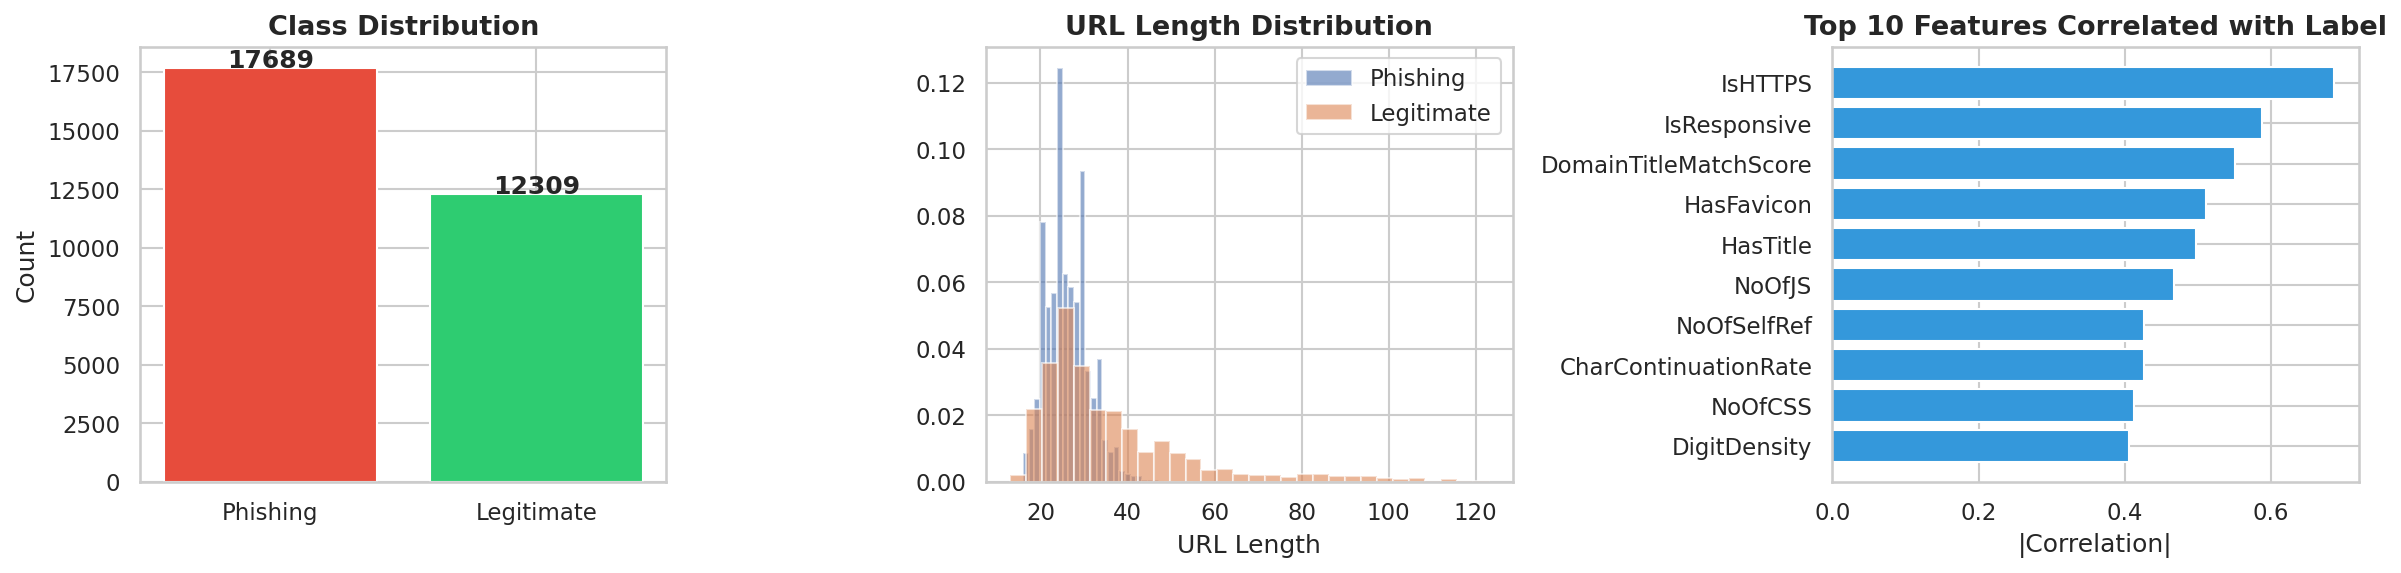

   Saved: 01_eda.png

[4/8] Training Classification Models...

  [4A] K-Nearest Neighbors
   KNN                   Acc=0.9907  P=0.9899  R=0.9943  F1=0.9921

  [4B] Support Vector Machine
   SVM                   Acc=0.9987  P=0.9977  R=1.0000  F1=0.9989

  [4C] Decision Tree
   Decision Tree         Acc=0.9963  P=0.9972  R=0.9966  F1=0.9969


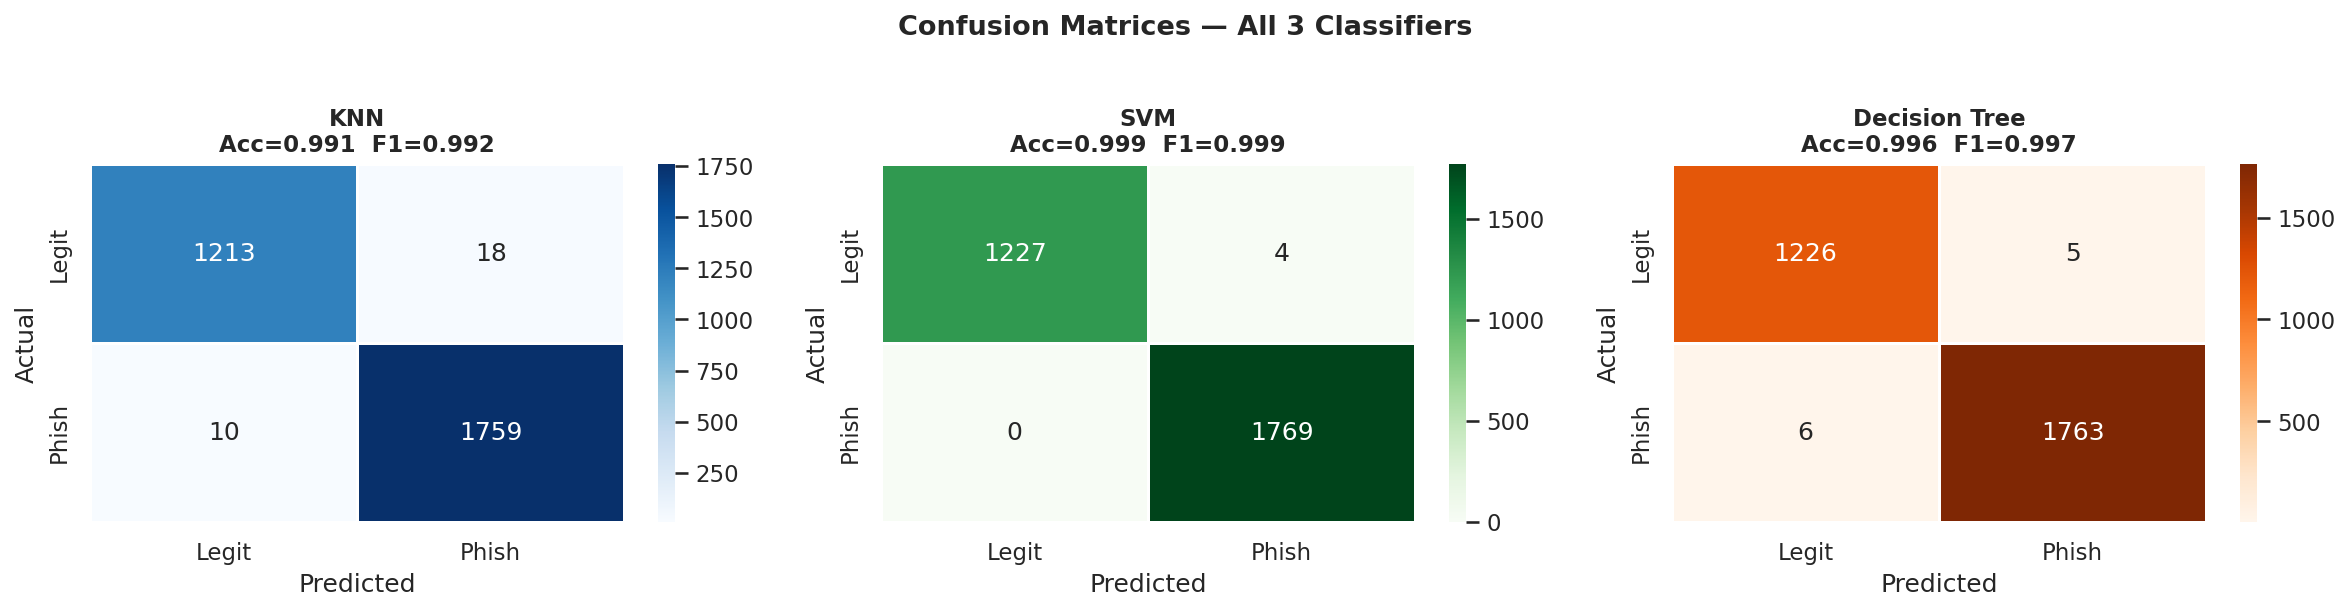

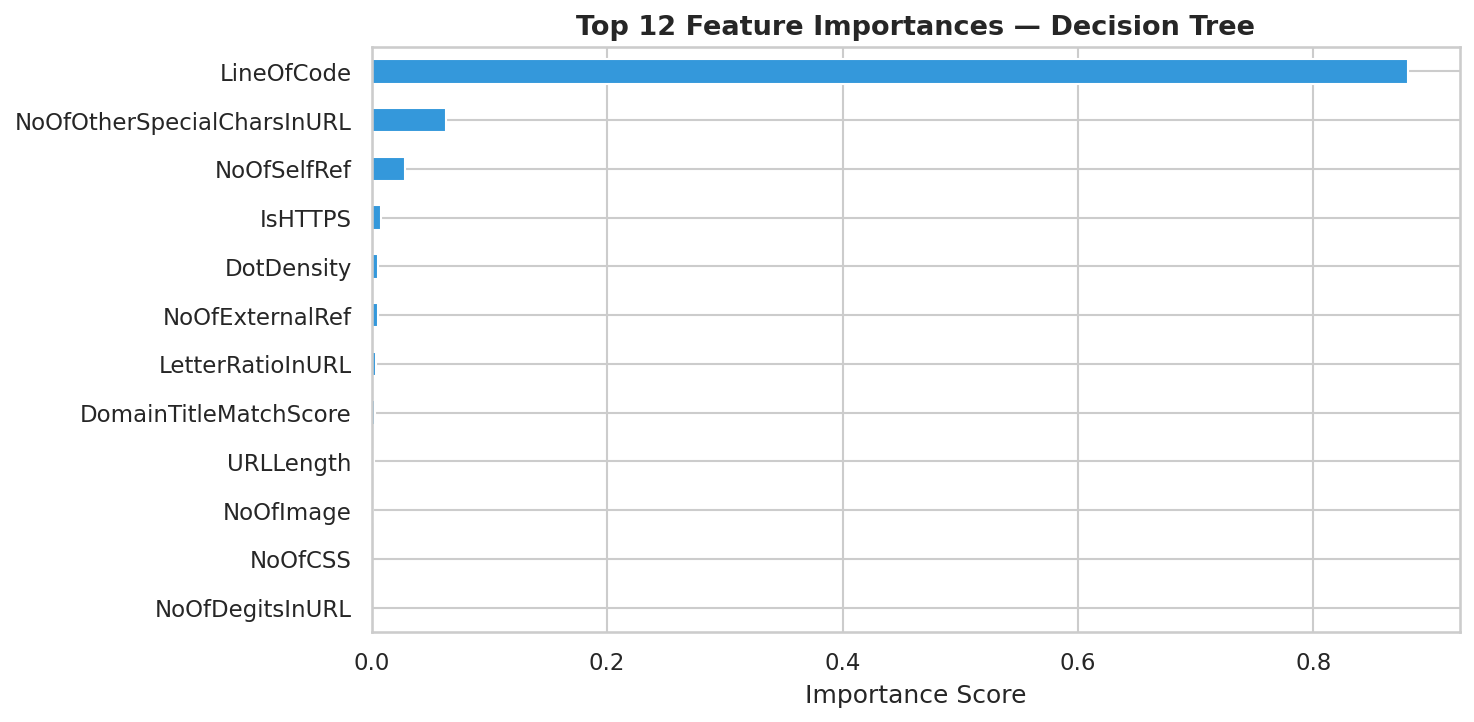

   Saved: 02_confusion_matrices.png + 03_feature_importance.png

[5/8] Linear Regression — Maliciousness Score
   RMSE=0.0397  MAE=0.0319  R²=-0.3754


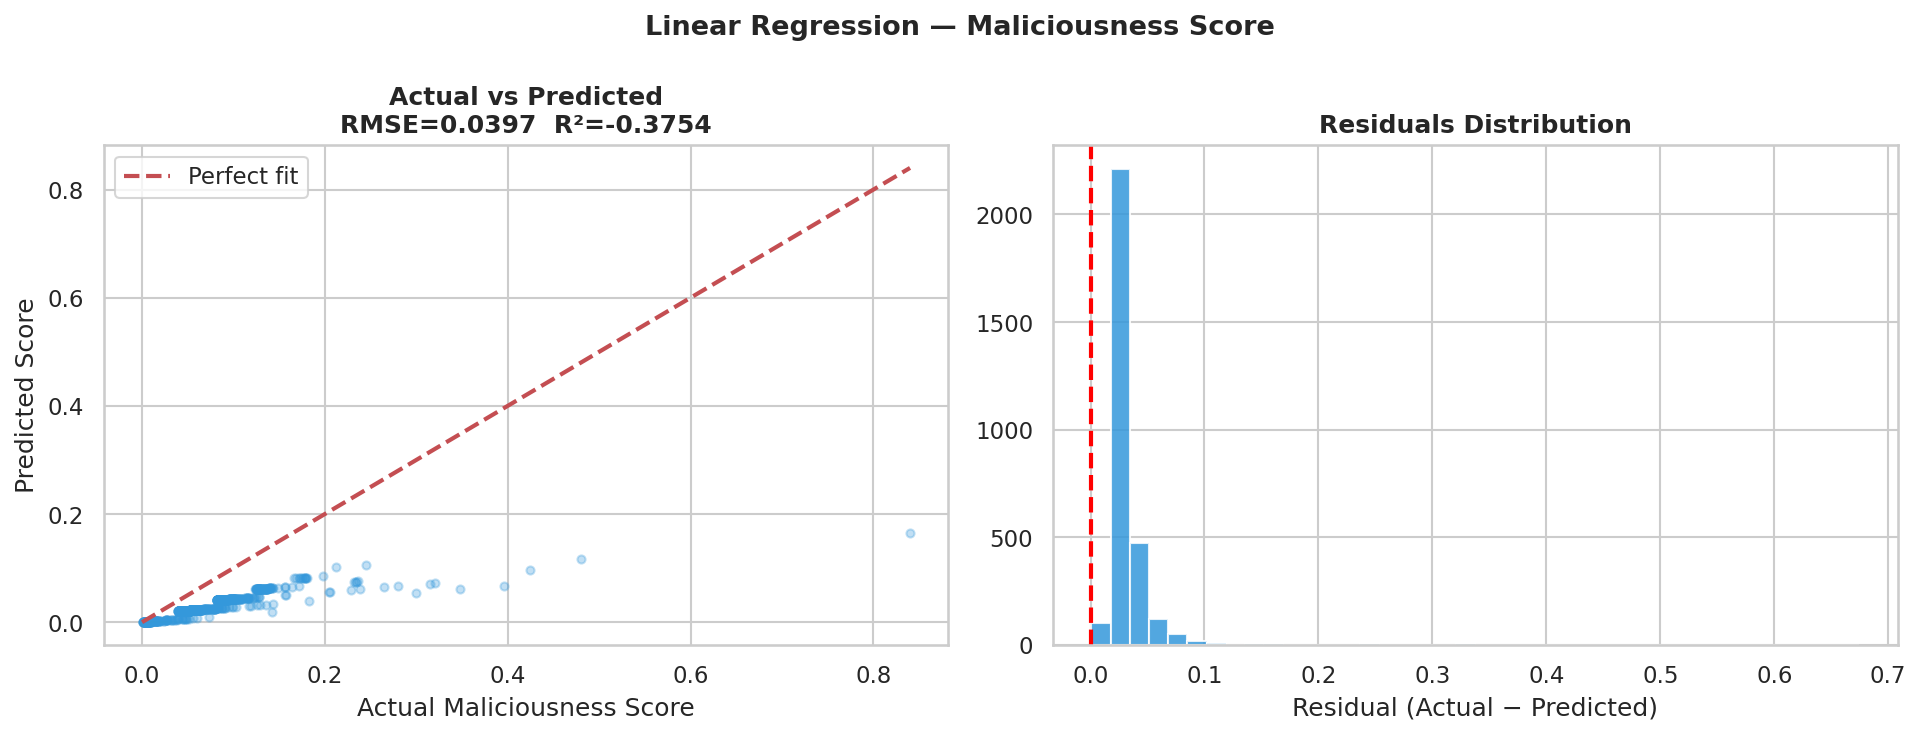

   Saved: 04_regression.png

[6/8] K-Means Clustering
   Best K : 2  (Silhouette=0.1466)
   Silhouette=0.1466  Davies-Bouldin=2.3391


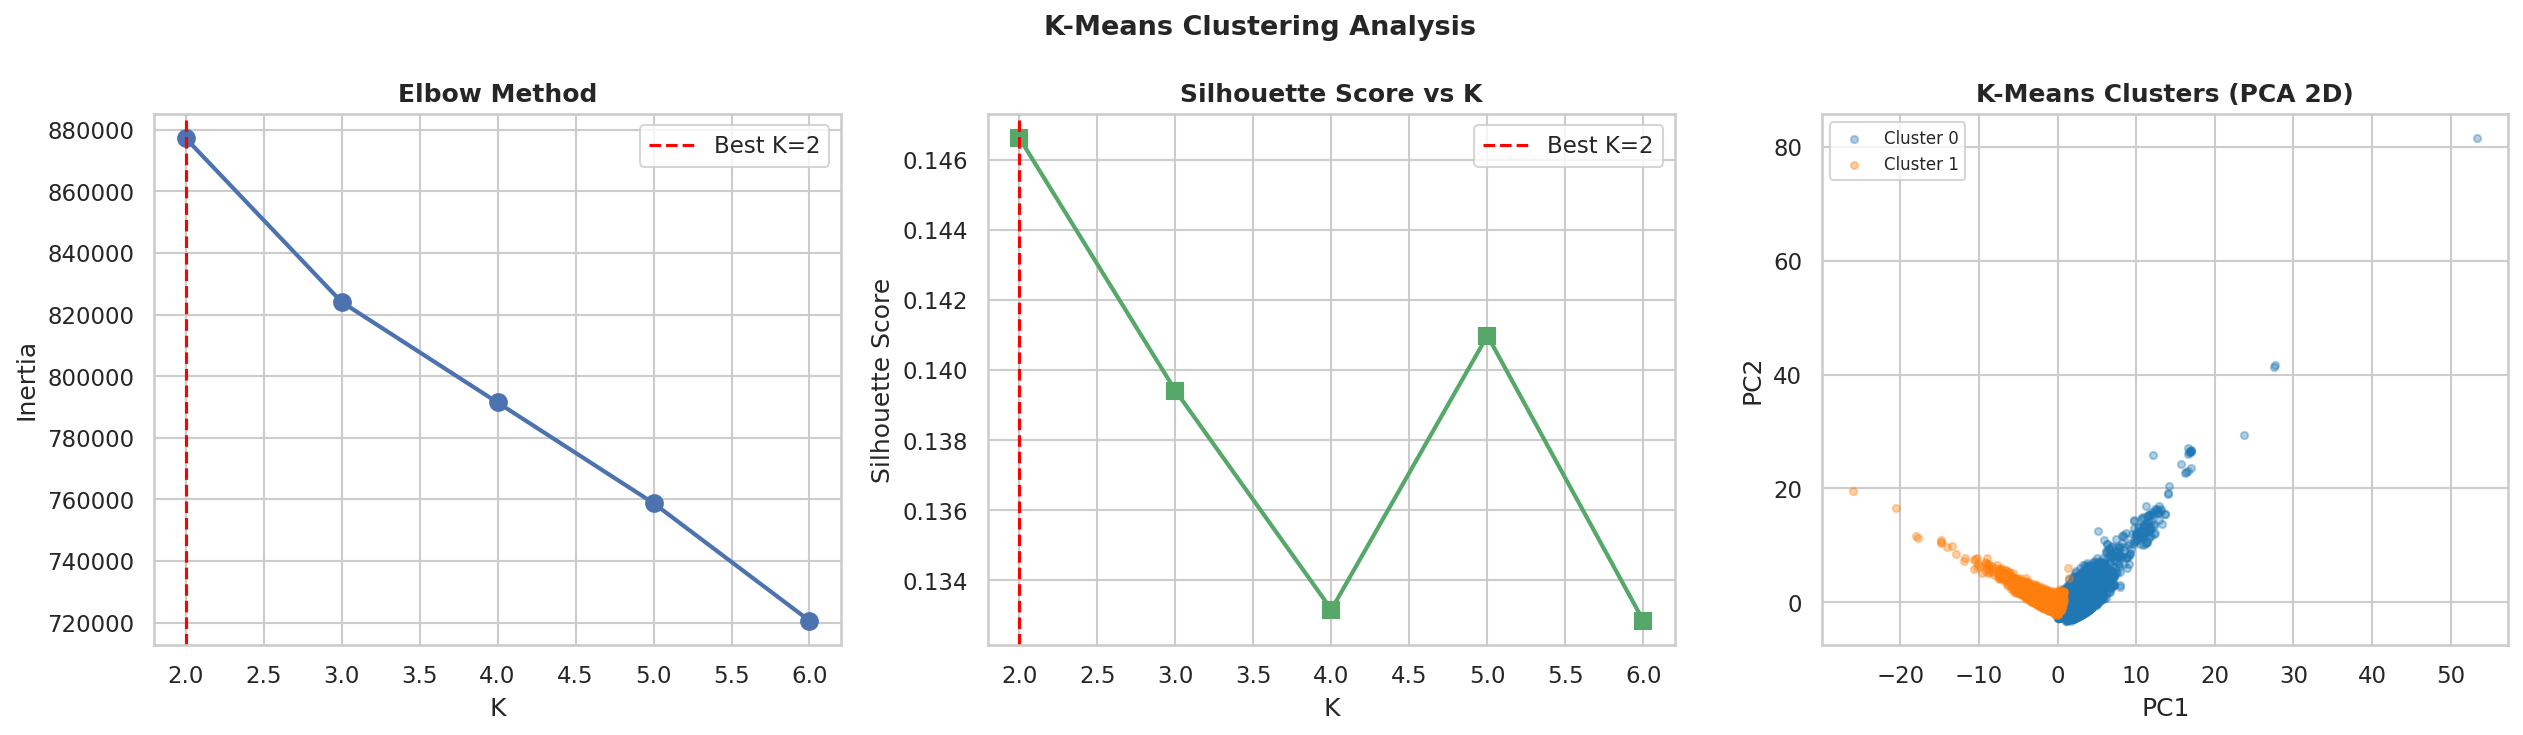

   Phishing rate per cluster:
     Cluster 0: 4.46%  → LEGIT-DOMINANT
     Cluster 1: 97.47%  → HIGH PHISHING
   Saved: 05_clustering.png

[7/8] Ensemble Learning

  [7A] Random Forest (Bagging)
   Random Forest         Acc=1.0000  P=1.0000  R=1.0000  F1=1.0000

  [7B] XGBoost (Boosting)
   XGBoost               Acc=1.0000  P=1.0000  R=1.0000  F1=1.0000


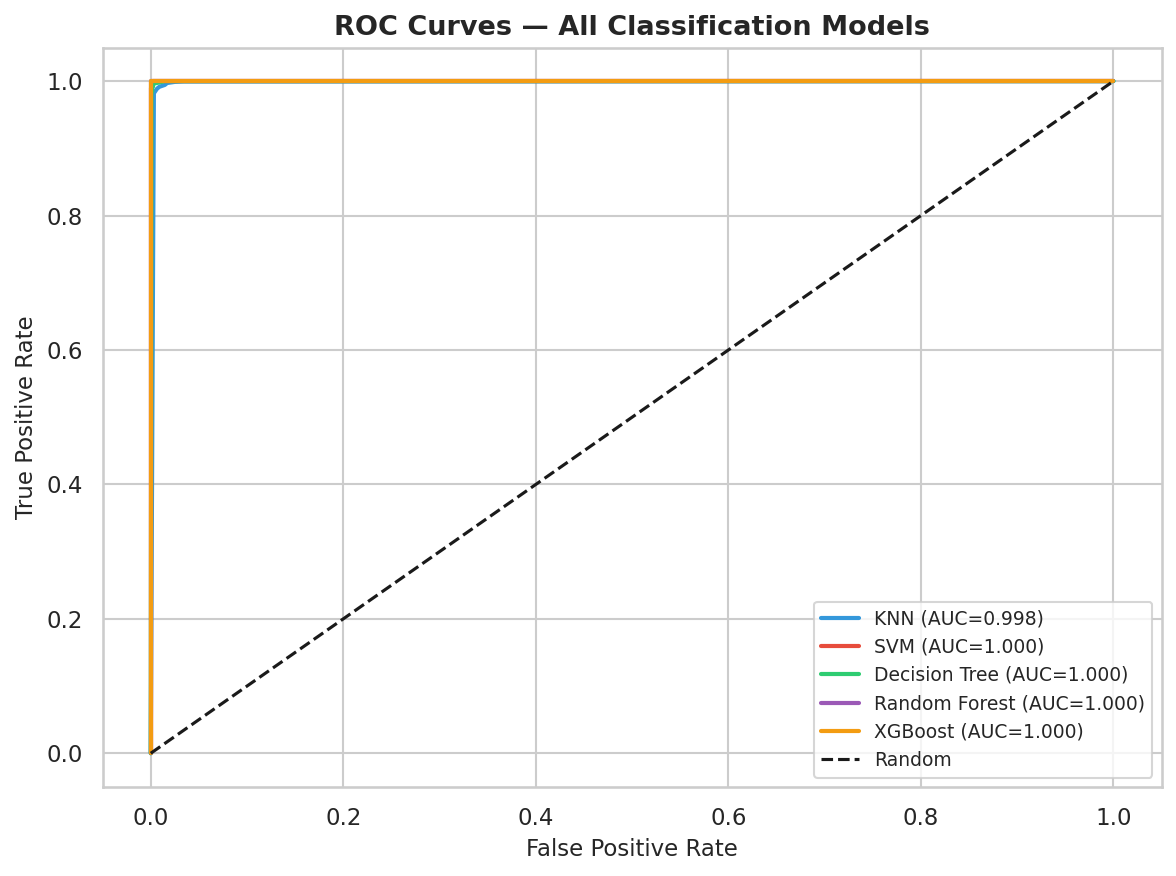

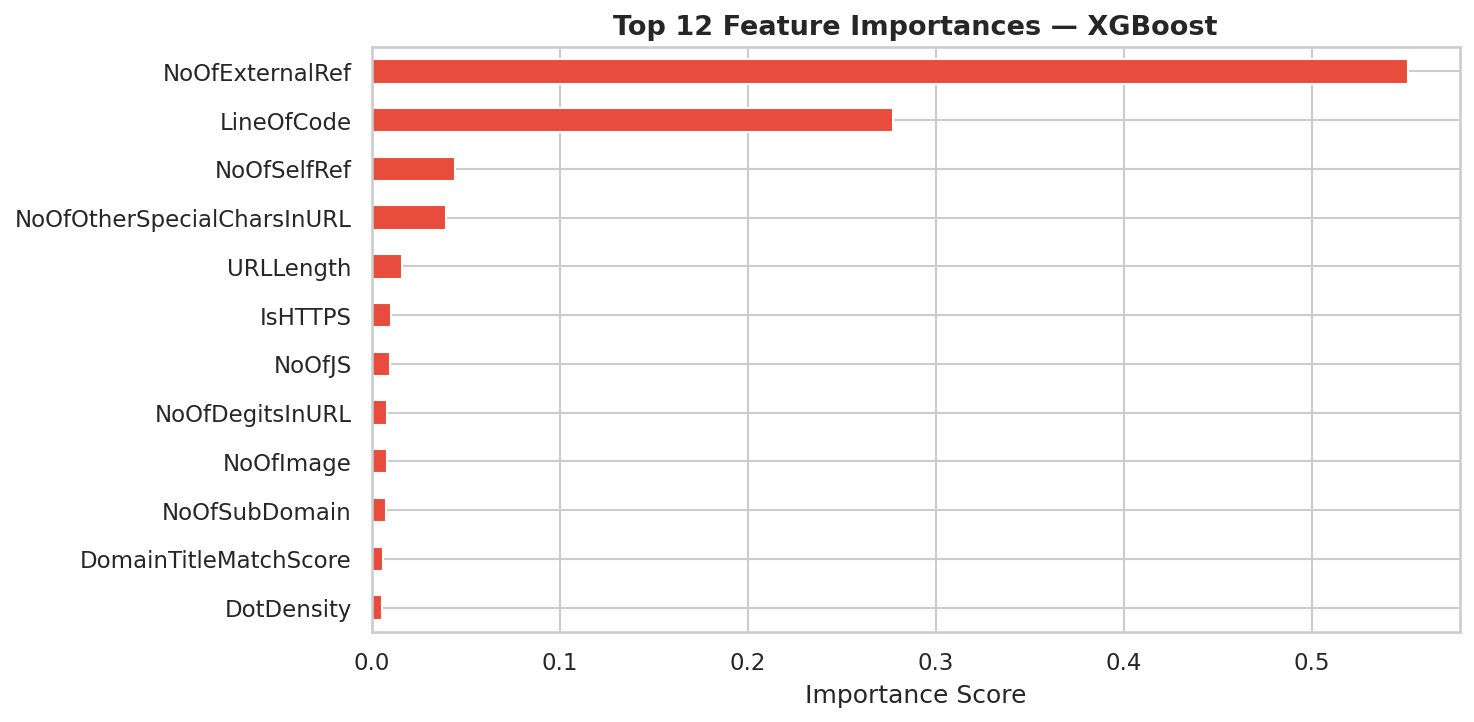

   Saved: 06_roc_curves.png + 07_xgb_importance.png

[8/8] Q-Learning — Sequential URL Feature Inspector
   Final avg reward : 7.59  |  Final eps : 0.0500
   Q-Agent: Accuracy=0.8610  F1=0.8932


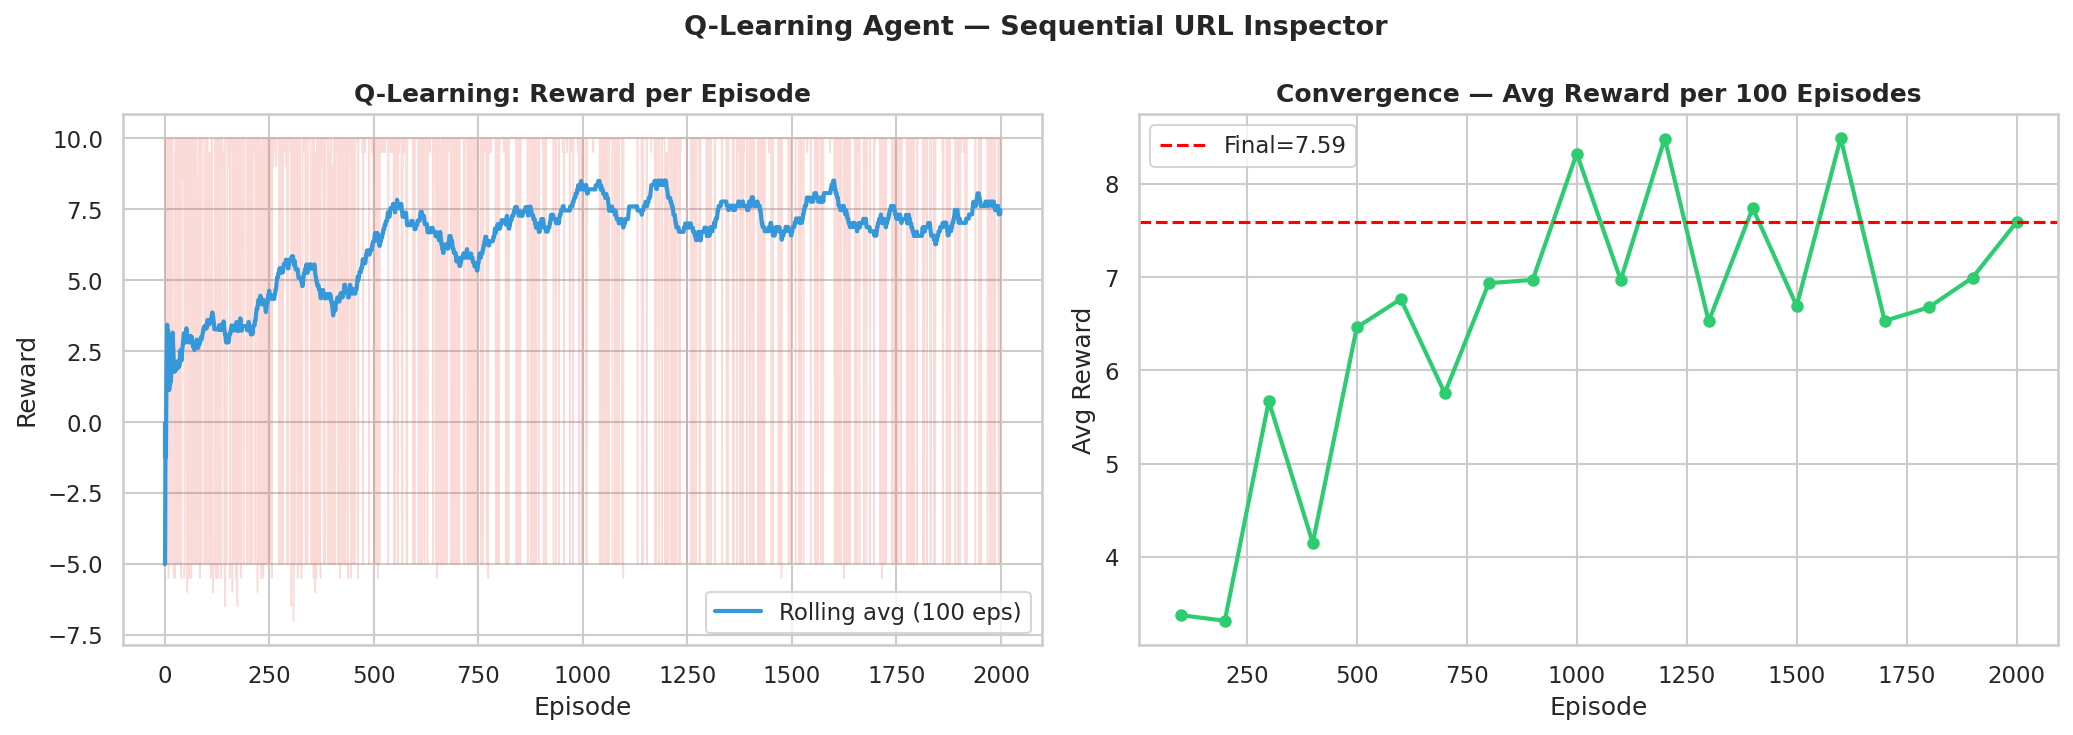

   Saved: 08_qlearning.png

  COMPARATIVE ANALYSIS SUMMARY

Model                  Accuracy  Precision     Recall   F1-Score
--------------------------------------------------------------
KNN                      0.9907     0.9899     0.9943     0.9921
SVM                      0.9987     0.9977     1.0000     0.9989
Decision Tree            0.9963     0.9972     0.9966     0.9969
Random Forest            1.0000     1.0000     1.0000     1.0000
XGBoost                  1.0000     1.0000     1.0000     1.0000

Regression:  RMSE=0.0397  MAE=0.0319  R²=-0.3754
Clustering:  Silhouette=0.1466  Davies-Bouldin=2.3391
Q-Learning:  Accuracy=0.8610  F1=0.8932  Avg Reward=7.59


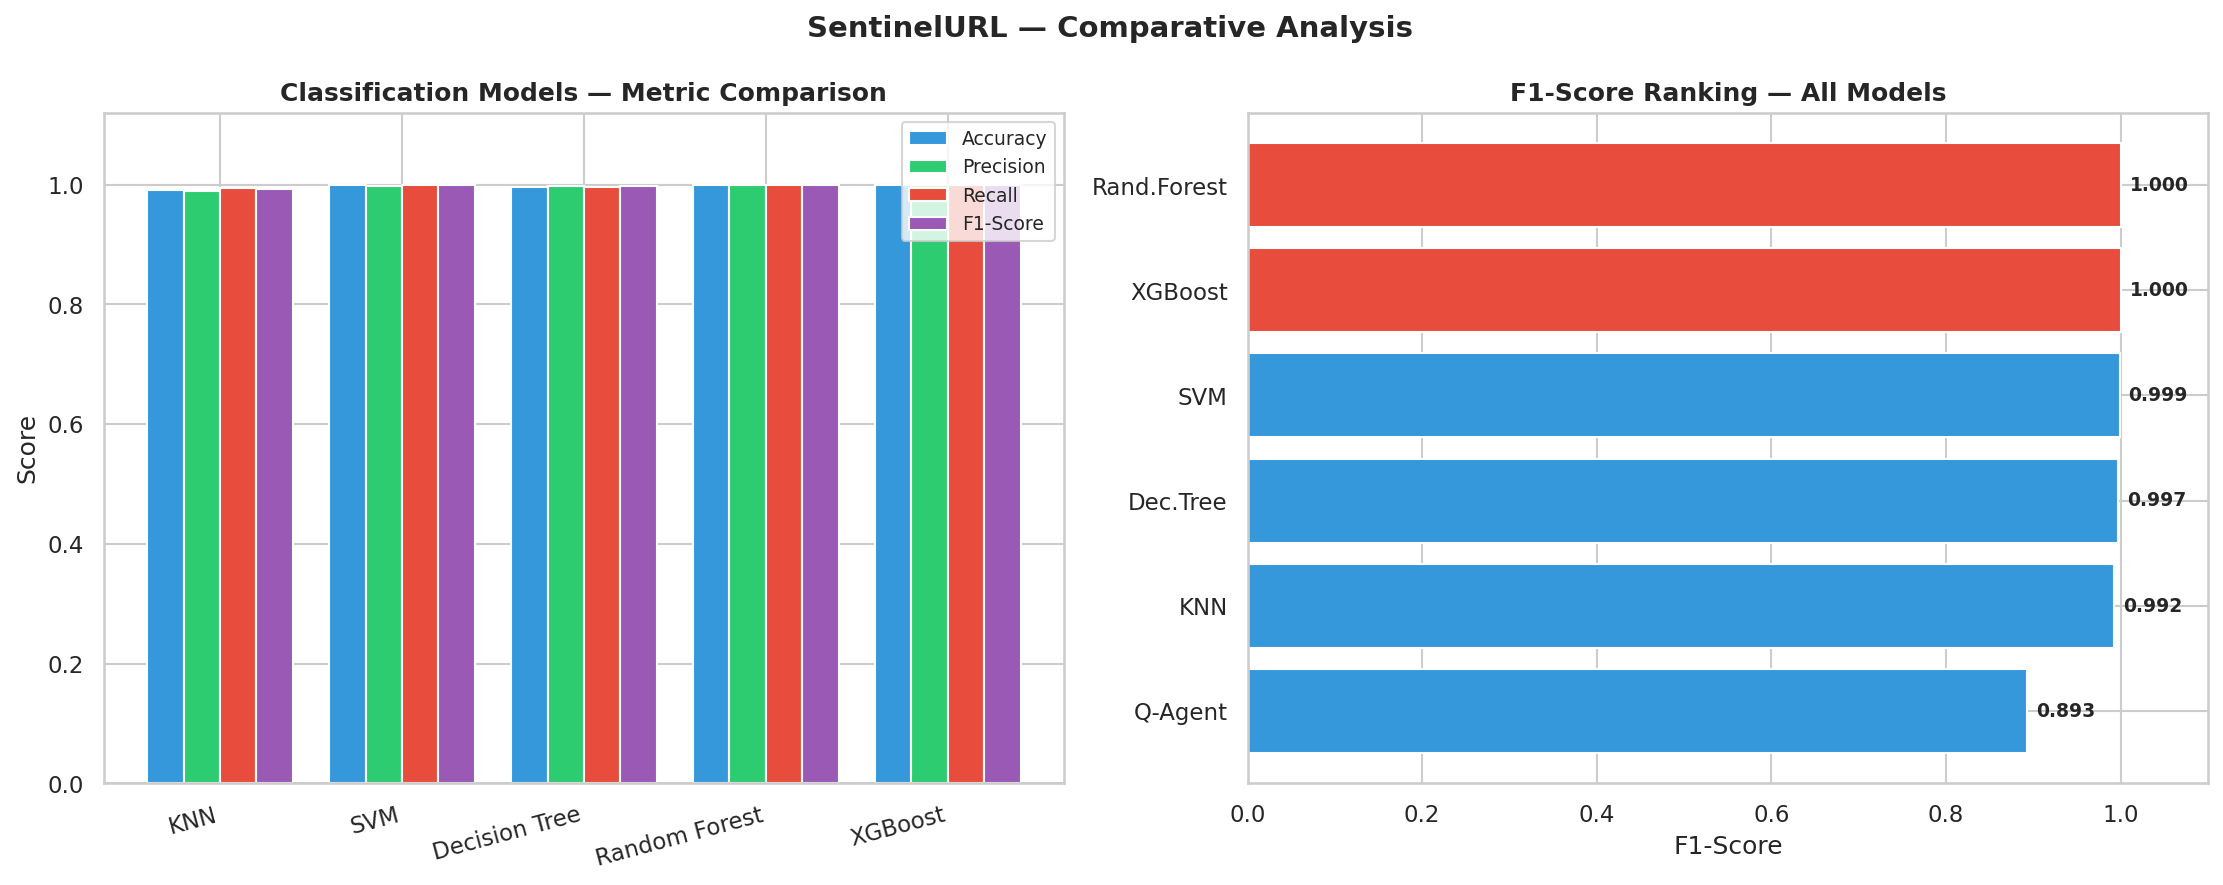


✅ ALL DONE! All 9 plots generated and displayed above.
💾 Models saved to sentinelurl_models.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📦 Downloads started — plots ZIP + models PKL


In [2]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
import os, pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix,
                              mean_squared_error, mean_absolute_error, r2_score,
                              silhouette_score, davies_bouldin_score, roc_curve, auc)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier
from IPython.display import display, Image

OUT = "/content/plots"
os.makedirs(OUT, exist_ok=True)
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="deep")
COLORS = {"phishing": "#E74C3C", "legit": "#2ECC71", "neutral": "#3498DB"}
results = {}

def clf_metrics(name, y_true, y_pred):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec  = recall_score(y_true, y_pred, zero_division=0)
    f1   = f1_score(y_true, y_pred, zero_division=0)
    results[name] = dict(Accuracy=acc, Precision=prec, Recall=rec, F1=f1)
    print(f"   {name:<20s}  Acc={acc:.4f}  P={prec:.4f}  R={rec:.4f}  F1={f1:.4f}")

print("=" * 60)
print("  SentinelURL — Phishing URL Detection")
print("=" * 60)

# =============================================================================
# SECTION 1 — LOAD DATASET
# =============================================================================
print("\n[1/8] Loading dataset...")
df = pd.read_csv('PhiUSIIL_Phishing_URL_Dataset.csv')
if 'label' not in df.columns:
    df.rename(columns={'phishing': 'label'}, inplace=True)
df = df.select_dtypes(include=[np.number])
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
print(f"   Dataset shape : {df.shape}")
print(f"   Phishing URLs : {(df.label==1).sum()}")
print(f"   Legit URLs    : {(df.label==0).sum()}")

# =============================================================================
# SECTION 2 — PREPROCESSING
# =============================================================================
print("\n[2/8] Preprocessing...")
print(f"   Missing values : {df.isnull().sum().sum()}")
print(f"   Duplicates     : {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)

# Stratified sample of 30,000 for speed
SAMPLE_SIZE = 30000
if len(df) > SAMPLE_SIZE:
    df = df.groupby("label", group_keys=False).apply(
        lambda x: x.sample(int(SAMPLE_SIZE * len(x) / len(df)), random_state=42)
    ).reset_index(drop=True)
    print(f"   Stratified sample : {len(df)} rows")

# Remove problematic features like URLSimilarityIndex and others to prevent data leakage
# These features are highly correlated with the label and may be derived from page content analysis, acting as proxies for the target variable.
problematic_features = ["label", "URLSimilarityIndex", "HasSocialNet", "HasCopyrightInfo", "HasDescription", "HasSubmitButton", "HasHiddenFields"]
X_raw = df.drop(columns=[f for f in problematic_features if f in df.columns], axis=1)
y = df["label"].values
feature_names = X_raw.columns.tolist()

# Remove near-zero variance
vt = VarianceThreshold(threshold=0.01)
X_vt = vt.fit_transform(X_raw)
kept = X_raw.columns[vt.get_support()].tolist()
X_raw = pd.DataFrame(X_vt, columns=kept)
feature_names = kept
print(f"   Features after variance filter    : {len(feature_names)}")

# Remove highly correlated (r > 0.95)
corr_matrix = X_raw.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if any(upper[col] > 0.95)]
X_raw.drop(columns=to_drop, inplace=True)
feature_names = X_raw.columns.tolist()
print(f"   Features after correlation filter : {len(feature_names)}")

# Derived features
X_raw["DotDensity"]   = X_raw["NoOfSubDomain"]  / (X_raw["URLLength"].replace(0,1))
X_raw["DigitDensity"] = X_raw["NoOfDegitsInURL"] / (X_raw["URLLength"].replace(0,1))
feature_names = X_raw.columns.tolist()

# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X_raw.values, y, test_size=0.1, stratify=y, random_state=42)
print(f"   Train size : {X_train.shape[0]}  |  Test size : {X_test.shape[0]}")

# Scale
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

# PCA
pca2 = PCA(n_components=2, random_state=42)
X_pca2 = pca2.fit_transform(X_train_s)
pca_full = PCA(n_components=0.95, random_state=42)
X_train_pca = pca_full.fit_transform(X_train_s)
X_test_pca  = pca_full.transform(X_test_s)
print(f"   PCA 95% variance : {X_train_pca.shape[1]} components")

# =============================================================================
# SECTION 3 — EDA
# =============================================================================
print("\n[3/8] EDA plots...")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
counts = [int((df.label==1).sum()), int((df.label==0).sum())]
axes[0].bar(["Phishing","Legitimate"], counts,
            color=[COLORS["phishing"], COLORS["legit"]], edgecolor="white")
axes[0].set_title("Class Distribution", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Count")
for i, v in enumerate(counts):
    axes[0].text(i, v+20, str(v), ha="center", fontweight="bold")
filtered = df[df["URLLength"] <= df["URLLength"].quantile(0.99)]

axes[1].hist(filtered[filtered.label==1]["URLLength"], bins=30,
             alpha=0.6, density=True, label="Phishing")

axes[1].hist(filtered[filtered.label==0]["URLLength"], bins=30,
             alpha=0.6, density=True, label="Legitimate")
axes[1].set_title("URL Length Distribution", fontsize=13, fontweight="bold")
axes[1].set_xlabel("URL Length"); axes[1].legend()
corr_df = X_raw.copy(); corr_df["label"] = y[:len(X_raw)]
top_corr = corr_df.corr()["label"].drop("label").abs().sort_values(ascending=False).head(10)
axes[2].barh(top_corr.index[::-1], top_corr.values[::-1], color=COLORS["neutral"])
axes[2].set_title("Top 10 Features Correlated with Label", fontsize=13, fontweight="bold")
axes[2].set_xlabel("|Correlation|")
plt.tight_layout()
plt.savefig(f"{OUT}/01_eda.png", dpi=150, bbox_inches="tight"); plt.close()
display(Image(f"{OUT}/01_eda.png"))
print("   Saved: 01_eda.png")

# =============================================================================
# SECTION 4 — CLASSIFICATION
# =============================================================================
print("\n[4/8] Training Classification Models...")

# KNN
print("\n  [4A] K-Nearest Neighbors")
knn = KNeighborsClassifier(n_neighbors=7, metric="euclidean", algorithm="ball_tree", n_jobs=-1)
knn.fit(X_train_s, y_train)
y_pred_knn = knn.predict(X_test_s)
clf_metrics("KNN", y_test, y_pred_knn)

# SVM
print("\n  [4B] Support Vector Machine")
lsvc = LinearSVC(C=1.0, max_iter=2000, random_state=42)
svm  = CalibratedClassifierCV(lsvc)
svm.fit(X_train_s, y_train)
y_pred_svm = svm.predict(X_test_s)
clf_metrics("SVM", y_test, y_pred_svm)

# Decision Tree
print("\n  [4C] Decision Tree")
dt = DecisionTreeClassifier(criterion="gini", max_depth=10, min_samples_leaf=20, random_state=42)
dt.fit(X_train_s, y_train)
y_pred_dt = dt.predict(X_test_s)
clf_metrics("Decision Tree", y_test, y_pred_dt)

# Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, y_pred, cmap) in zip(axes, [
    ("KNN", y_pred_knn, "Blues"),
    ("SVM", y_pred_svm, "Greens"),
    ("Decision Tree", y_pred_dt, "Oranges")]):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, ax=ax,
                xticklabels=["Legit","Phish"], yticklabels=["Legit","Phish"],
                linewidths=0.5, linecolor="white")
    ax.set_title(f"{name}\nAcc={accuracy_score(y_test,y_pred):.3f}  F1={f1_score(y_test,y_pred):.3f}",
                 fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.suptitle("Confusion Matrices — All 3 Classifiers", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{OUT}/02_confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.close()
display(Image(f"{OUT}/02_confusion_matrices.png"))

# Feature Importance
fi = pd.Series(dt.feature_importances_, index=feature_names).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(10, 5))
fi[::-1].plot(kind="barh", ax=ax, color=COLORS["neutral"], edgecolor="white")
ax.set_title("Top 12 Feature Importances — Decision Tree", fontsize=13, fontweight="bold")
ax.set_xlabel("Importance Score")
plt.tight_layout()
plt.savefig(f"{OUT}/03_feature_importance.png", dpi=150, bbox_inches="tight"); plt.close()
display(Image(f"{OUT}/03_feature_importance.png"))
print("   Saved: 02_confusion_matrices.png + 03_feature_importance.png")

# =============================================================================
# SECTION 5 — REGRESSION
# =============================================================================
print("\n[5/8] Linear Regression — Maliciousness Score")
def make_mal_score(X_df):
    score, total_w = np.zeros(len(X_df)), 0
    weights = {"URLLength":0.20,"NoOfObfuscatedChar":0.20,"IsDomainIP":0.15,
               "ObfuscationRatio":0.15,"NoOfSubDomain":0.10,"HasObfuscation":0.10,"DegitRatioInURL":0.10}
    for feat, w in weights.items():
        if feat in X_df.columns:
            col  = X_df[feat].values.astype(float)
            norm = (col - col.min()) / (col.max() - col.min() + 1e-9)
            score += w * norm; total_w += w
    return (score / (total_w + 1e-9)).clip(0, 1)

X_df_train  = pd.DataFrame(X_train, columns=feature_names)
X_df_test   = pd.DataFrame(X_test,  columns=feature_names)
y_reg_train = make_mal_score(X_df_train)
y_reg_test  = make_mal_score(X_df_test)
lr = LinearRegression()
lr.fit(X_train_s, y_reg_train)
y_pred_reg = lr.predict(X_test_s)
rmse = np.sqrt(mean_squared_error(y_reg_test, y_pred_reg))
mae  = mean_absolute_error(y_reg_test, y_pred_reg)
r2   = r2_score(y_reg_test, y_pred_reg)
results["Linear Regression"] = dict(RMSE=rmse, MAE=mae, R2=r2)
print(f"   RMSE={rmse:.4f}  MAE={mae:.4f}  R²={r2:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_reg_test, y_pred_reg, alpha=0.3, color=COLORS["neutral"], s=15)
mn, mx = min(y_reg_test.min(),y_pred_reg.min()), max(y_reg_test.max(),y_pred_reg.max())
axes[0].plot([mn,mx],[mn,mx], "r--", linewidth=2, label="Perfect fit")
axes[0].set_xlabel("Actual Maliciousness Score"); axes[0].set_ylabel("Predicted Score")
axes[0].set_title(f"Actual vs Predicted\nRMSE={rmse:.4f}  R²={r2:.4f}", fontweight="bold")
axes[0].legend()
residuals = y_reg_test - y_pred_reg
axes[1].hist(residuals, bins=40, color=COLORS["neutral"], edgecolor="white", alpha=0.85)
axes[1].axvline(0, color="red", linestyle="--", linewidth=2)
axes[1].set_title("Residuals Distribution", fontweight="bold")
axes[1].set_xlabel("Residual (Actual − Predicted)")
plt.suptitle("Linear Regression — Maliciousness Score", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT}/04_regression.png", dpi=150, bbox_inches="tight"); plt.close()
display(Image(f"{OUT}/04_regression.png"))
print("   Saved: 04_regression.png")

# =============================================================================
# SECTION 6 — CLUSTERING
# =============================================================================
print("\n[6/8] K-Means Clustering")
inertias, sil_scores, k_range = [], [], range(2, 7)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=5, max_iter=100)
    labels_k = km.fit_predict(X_train_pca)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_train_pca, labels_k))
best_k = list(k_range)[np.argmax(sil_scores)]
print(f"   Best K : {best_k}  (Silhouette={max(sil_scores):.4f})")
km_final = KMeans(n_clusters=best_k, random_state=42, n_init=5, max_iter=100)
cluster_labels = km_final.fit_predict(X_train_pca)
db_score  = davies_bouldin_score(X_train_pca, cluster_labels)
sil_final = silhouette_score(X_train_pca, cluster_labels)
results["K-Means"] = dict(Silhouette=sil_final, Davies_Bouldin=db_score)
print(f"   Silhouette={sil_final:.4f}  Davies-Bouldin={db_score:.4f}")
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].plot(list(k_range), inertias, "bo-", linewidth=2, markersize=8)
axes[0].set_title("Elbow Method", fontweight="bold")
axes[0].set_xlabel("K"); axes[0].set_ylabel("Inertia")
axes[0].axvline(best_k, color="red", linestyle="--", label=f"Best K={best_k}"); axes[0].legend()
axes[1].plot(list(k_range), sil_scores, "gs-", linewidth=2, markersize=8)
axes[1].set_title("Silhouette Score vs K", fontweight="bold")
axes[1].set_xlabel("K"); axes[1].set_ylabel("Silhouette Score")
axes[1].axvline(best_k, color="red", linestyle="--", label=f"Best K={best_k}"); axes[1].legend()
X_vis = pca2.transform(X_train_s[:len(cluster_labels)])
palette = sns.color_palette("tab10", best_k)
for c in range(best_k):
    mask = cluster_labels == c
    axes[2].scatter(X_vis[mask,0], X_vis[mask,1], color=palette[c], alpha=0.35, s=12, label=f"Cluster {c}")
axes[2].set_title("K-Means Clusters (PCA 2D)", fontweight="bold")
axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2"); axes[2].legend(fontsize=8)
plt.suptitle("K-Means Clustering Analysis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT}/05_clustering.png", dpi=150, bbox_inches="tight"); plt.close()
display(Image(f"{OUT}/05_clustering.png"))
cluster_df = pd.DataFrame(X_train, columns=feature_names)
cluster_df["cluster"] = cluster_labels
cluster_df["true_label"] = y_train[:len(cluster_labels)]
phish_rate = cluster_df.groupby("cluster")["true_label"].mean()
print("   Phishing rate per cluster:")
for c, rate in phish_rate.items():
    tag = "HIGH PHISHING" if rate > 0.6 else ("MIXED" if rate > 0.4 else "LEGIT-DOMINANT")
    print(f"     Cluster {c}: {rate:.2%}  → {tag}")
print("   Saved: 05_clustering.png")

# =============================================================================
# SECTION 7 — ENSEMBLE
# =============================================================================
print("\n[7/8] Ensemble Learning")
print("\n  [7A] Random Forest (Bagging)")
rf = RandomForestClassifier(n_estimators=50, max_depth=10, min_samples_leaf=10, n_jobs=-1, random_state=42)
rf.fit(X_train_s, y_train)
y_pred_rf = rf.predict(X_test_s)
clf_metrics("Random Forest", y_test, y_pred_rf)

print("\n  [7B] XGBoost (Boosting)")
xgb = XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1,
                     subsample=0.8, colsample_bytree=0.8,
                     use_label_encoder=False, eval_metric="logloss",
                     random_state=42, n_jobs=-1, verbosity=0, tree_method="hist")
xgb.fit(X_train_s, y_train, eval_set=[(X_test_s, y_test)], verbose=False)
y_pred_xgb = xgb.predict(X_test_s)
clf_metrics("XGBoost", y_test, y_pred_xgb)

# ROC Curves
fig, ax = plt.subplots(figsize=(8, 6))
for (name, proba), color in zip([
    ("KNN",           knn.predict_proba(X_test_s)[:,1]),
    ("SVM",           svm.predict_proba(X_test_s)[:,1]),
    ("Decision Tree", dt.predict_proba(X_test_s)[:,1]),
    ("Random Forest", rf.predict_proba(X_test_s)[:,1]),
    ("XGBoost",       xgb.predict_proba(X_test_s)[:,1]),
], ["#3498DB","#E74C3C","#2ECC71","#9B59B6","#F39C12"]):
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} (AUC={auc(fpr,tpr):.3f})")
ax.plot([0,1],[0,1], "k--", linewidth=1.5, label="Random")
ax.set_xlabel("False Positive Rate", fontsize=11); ax.set_ylabel("True Positive Rate", fontsize=11)
ax.set_title("ROC Curves — All Classification Models", fontsize=13, fontweight="bold")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUT}/06_roc_curves.png", dpi=150, bbox_inches="tight"); plt.close()
display(Image(f"{OUT}/06_roc_curves.png"))

# XGBoost Feature Importance
xgb_fi = pd.Series(xgb.feature_importances_, index=feature_names).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(10, 5))
xgb_fi[::-1].plot(kind="barh", ax=ax, color=COLORS["phishing"], edgecolor="white")
ax.set_title("Top 12 Feature Importances — XGBoost", fontsize=13, fontweight="bold")
ax.set_xlabel("Importance Score")
plt.tight_layout()
plt.savefig(f"{OUT}/07_xgb_importance.png", dpi=150, bbox_inches="tight"); plt.close()
display(Image(f"{OUT}/07_xgb_importance.png"))
print("   Saved: 06_roc_curves.png + 07_xgb_importance.png")

# =============================================================================
# SECTION 8 — Q-LEARNING
# =============================================================================
print("\n[8/8] Q-Learning — Sequential URL Feature Inspector")
class URLInspectorEnv:
    def __init__(self, X, y):
        self.X = X; self.y = y
        self.n_states = 36; self.n_actions = 3
        self.col_idx = {}
        for feat, pos in [("URLLength",0),("IsHTTPS",1),("NoOfSubDomain",2),("IsDomainIP",3)]:
            if feat in feature_names:
                self.col_idx[pos] = feature_names.index(feat)
    def _encode_state(self, row):
        b_len = 0 if row[self.col_idx.get(0,0)] < 50 else (1 if row[self.col_idx.get(0,0)] < 100 else 2)
        https = int(row[self.col_idx.get(1,1)]) & 1
        nsub  = row[self.col_idx.get(2,2)]
        b_sub = 0 if nsub==0 else (1 if nsub<=2 else 2)
        is_ip = int(row[self.col_idx.get(3,3)]) & 1
        return b_len*12 + https*6 + b_sub*2 + is_ip
    def reset(self):
        self.ep_idx = np.random.randint(0, len(self.X))
        self.true_label = self.y[self.ep_idx]
        self.steps = 0; self.done = False
        return self._encode_state(self.X[self.ep_idx])
    def step(self, action):
        if self.done: return 0, 0, True, {}
        self.steps += 1
        if action == 0:   reward=-0.5; done=self.steps>=6
        elif action == 1: reward=10 if self.true_label==1 else -5; done=True
        else:             reward=10 if self.true_label==0 else -5; done=True
        self.done = done
        return self._encode_state(self.X[self.ep_idx]), reward, done, {}

env = URLInspectorEnv(X_train_s, y_train)
Q   = np.zeros((env.n_states, env.n_actions))
alpha=0.15; gamma=0.90; eps=1.0; eps_min=0.05; eps_decay=0.998; EPISODES=2000
rewards_per_ep=[]; avg_rewards=[]
for ep in range(EPISODES):
    state=env.reset(); ep_reward=0; done=False
    while not done:
        action = np.random.randint(env.n_actions) if np.random.random()<eps else np.argmax(Q[state])
        next_state,reward,done,_ = env.step(action)
        Q[state,action] += alpha*(reward + gamma*np.max(Q[next_state]) - Q[state,action])
        state=next_state; ep_reward+=reward
    eps=max(eps_min, eps*eps_decay); rewards_per_ep.append(ep_reward)
    if (ep+1)%100==0: avg_rewards.append(np.mean(rewards_per_ep[-100:]))

print(f"   Final avg reward : {np.mean(rewards_per_ep[-100:]):.2f}  |  Final eps : {eps:.4f}")
env_test=URLInspectorEnv(X_test_s, y_test); q_preds=[]; q_true=[]
for _ in range(min(1000, len(X_test_s))):
    state=env_test.reset(); done=False; final_action=2
    while not done:
        action=np.argmax(Q[state]); state,_,done,_=env_test.step(action)
        if action in [1,2]: final_action=action
    q_preds.append(1 if final_action==1 else 0); q_true.append(env_test.true_label)
q_acc=accuracy_score(q_true,q_preds); q_f1=f1_score(q_true,q_preds,zero_division=0)
results["Q-Learning"]=dict(Accuracy=q_acc, F1=q_f1, Avg_Reward=float(np.mean(rewards_per_ep[-100:])))
print(f"   Q-Agent: Accuracy={q_acc:.4f}  F1={q_f1:.4f}")
window=100
rolling_avg=[np.mean(rewards_per_ep[max(0,i-window):i+1]) for i in range(len(rewards_per_ep))]
fig, axes=plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(rewards_per_ep, alpha=0.2, color=COLORS["phishing"], linewidth=0.7)
axes[0].plot(rolling_avg, color=COLORS["neutral"], linewidth=2, label=f"Rolling avg ({window} eps)")
axes[0].set_title("Q-Learning: Reward per Episode", fontweight="bold")
axes[0].set_xlabel("Episode"); axes[0].set_ylabel("Reward"); axes[0].legend()
ep_ticks=list(range(100,EPISODES+1,100))
axes[1].plot(ep_ticks, avg_rewards, "o-", color=COLORS["legit"], linewidth=2, markersize=5)
axes[1].set_title("Convergence — Avg Reward per 100 Episodes", fontweight="bold")
axes[1].set_xlabel("Episode"); axes[1].set_ylabel("Avg Reward")
axes[1].axhline(avg_rewards[-1], color="red", linestyle="--", label=f"Final={avg_rewards[-1]:.2f}")
axes[1].legend()
plt.suptitle("Q-Learning Agent — Sequential URL Inspector", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT}/08_qlearning.png", dpi=150, bbox_inches="tight"); plt.close()
display(Image(f"{OUT}/08_qlearning.png"))
print("   Saved: 08_qlearning.png")

# =============================================================================
# SECTION 9 — COMPARATIVE ANALYSIS
# =============================================================================
print("\n" + "="*60)
print("  COMPARATIVE ANALYSIS SUMMARY")
print("="*60)
clf_names=["KNN","SVM","Decision Tree","Random Forest","XGBoost"]
acc_vals=[results[n]["Accuracy"] for n in clf_names]
prec_vals=[results[n]["Precision"] for n in clf_names]
rec_vals=[results[n]["Recall"] for n in clf_names]
f1_vals=[results[n]["F1"] for n in clf_names]
print(f"\n{'Model':<20} {'Accuracy':>10} {'Precision':>10} {'Recall':>10} {'F1-Score':>10}")
print("-"*62)
for n,a,p,r,f in zip(clf_names,acc_vals,prec_vals,rec_vals,f1_vals):
    print(f"{n:<20} {a:>10.4f} {p:>10.4f} {r:>10.4f} {f:>10.4f}")
lr_r=results["Linear Regression"]
print(f"\nRegression:  RMSE={lr_r['RMSE']:.4f}  MAE={lr_r['MAE']:.4f}  R²={lr_r['R2']:.4f}")
km_r=results["K-Means"]
print(f"Clustering:  Silhouette={km_r['Silhouette']:.4f}  Davies-Bouldin={km_r['Davies_Bouldin']:.4f}")
ql_r=results["Q-Learning"]
print(f"Q-Learning:  Accuracy={ql_r['Accuracy']:.4f}  F1={ql_r['F1']:.4f}  Avg Reward={ql_r['Avg_Reward']:.2f}")

fig, axes=plt.subplots(1, 2, figsize=(15, 6))
x=np.arange(len(clf_names)); w=0.2
axes[0].bar(x-1.5*w,acc_vals, w,label="Accuracy", color="#3498DB",edgecolor="white")
axes[0].bar(x-0.5*w,prec_vals,w,label="Precision",color="#2ECC71",edgecolor="white")
axes[0].bar(x+0.5*w,rec_vals, w,label="Recall",   color="#E74C3C",edgecolor="white")
axes[0].bar(x+1.5*w,f1_vals,  w,label="F1-Score", color="#9B59B6",edgecolor="white")
axes[0].set_xticks(x); axes[0].set_xticklabels(clf_names,rotation=15,ha="right")
axes[0].set_ylim(0,1.12); axes[0].set_title("Classification Models — Metric Comparison",fontsize=12,fontweight="bold")
axes[0].set_ylabel("Score"); axes[0].legend(fontsize=9)
f1_all={"KNN":results["KNN"]["F1"],"SVM":results["SVM"]["F1"],
        "Dec.Tree":results["Decision Tree"]["F1"],
        "Rand.Forest":results["Random Forest"]["F1"],
        "XGBoost":results["XGBoost"]["F1"],
        "Q-Agent":results["Q-Learning"]["F1"]}
sorted_f1=dict(sorted(f1_all.items(),key=lambda x:x[1],reverse=True))
bar_colors=[COLORS["phishing"] if v==max(sorted_f1.values()) else COLORS["neutral"] for v in sorted_f1.values()]
axes[1].barh(list(sorted_f1.keys())[::-1],list(sorted_f1.values())[::-1],color=bar_colors[::-1],edgecolor="white")
axes[1].set_title("F1-Score Ranking — All Models",fontsize=12,fontweight="bold")
axes[1].set_xlabel("F1-Score"); axes[1].set_xlim(0,1.1)
for i,(k,v) in enumerate(reversed(list(sorted_f1.items()))):
    axes[1].text(v+0.01,i,f"{v:.3f}",va="center",fontsize=9,fontweight="bold")
plt.suptitle("SentinelURL — Comparative Analysis",fontsize=14,fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT}/09_comparative_analysis.png",dpi=150,bbox_inches="tight"); plt.close()
display(Image(f"{OUT}/09_comparative_analysis.png"))
print("\n✅ ALL DONE! All 9 plots generated and displayed above.")

# =============================================================================
# SAVE MODELS
# =============================================================================
models_to_save = {
    'knn':knn,'svm':svm,'dt':dt,'rf':rf,'xgb':xgb,'lr':lr,'km':km_final,
    'Q_table':Q,'scaler':scaler,'pca2':pca2,'pca_full':pca_full,
    'feature_names':feature_names,'results':results
}
with open('/content/sentinelurl_models.pkl','wb') as f:
    pickle.dump(models_to_save, f)
print("💾 Models saved to sentinelurl_models.pkl")

# =============================================================================
# DOWNLOAD EVERYTHING
# =============================================================================
import shutil
from google.colab import files
shutil.make_archive('SentinelURL_plots','zip','/content/plots')
files.download('SentinelURL_plots.zip')
files.download('/content/sentinelurl_models.pkl')
print("📦 Downloads started — plots ZIP + models PKL")
